# Week 2: Feature Engineering Report + Pipeline Notebook

## 1. Feature Summary Table

| Original Feature | Engineering Decision | Justification |
| :--- | :--- | :--- |
| `instant` | Remove | No relationship to hourly bike rental demand. |
| `dteday` | Remove | Raw date string redundant with `yr`, `mnth`, and `weekday`, which causes overfitting. |
| `season` | Encode (One-Hot) | Nominal meteorological season (1–4) with non-monotonic rental effects across seasons. |
| `yr` | Keep as-is | Binary year indicator (`0` = 2011, `1` = 2012) capturing year-over-year ridership growth. |
| `mnth` | Transform (Cyclical) & Remove raw | Cyclical `sin`/`cos` encoding preserves continuity between December (12) and January (1). |
| `hr` | Transform (Cyclical) & Remove raw | Cyclical `sin`/`cos` encoding preserves midnight continuity (`23:00` to `00:00`). |
| `holiday` | Keep as-is | Binary indicator capturing demand patterns on public holidays. |
| `weekday` | Encode (One-Hot) | To distinguish commuter vs. weekend usage patterns. |
| `workingday` | Keep as-is | To distinguish commuter vs. weekend usage patterns. |
| `weathersit` | Encode (One-Hot) | Categorical weather severity (1–4) affecting rider comfort and hourly volume non-linearly. |
| `temp` | Keep as-is (Scale in Pipeline) | Normalized ambient temperature drives outdoor cycling activity. |
| `atemp` | Remove (Correlation Analysis) | Feeling temperature is collinear with `temp`. |
| `hum` | Keep as-is (Scale in Pipeline) | Normalized humidity reduces rider comfort. |
| `windspeed` | Keep as-is (Scale in Pipeline) | Normalized wind speed affects cycling demand. |
| `casual` | Remove | Direct additive component of target `cnt` (`casual + registered = cnt`).|
| `registered` | Remove | Direct additive component of target `cnt` (`casual + registered = cnt`). |

## 2. Data Loading & Initial Inspection

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('../data/raw/hour.csv')

print('Dataset shape:', df.shape)
display(df.head())

Dataset shape: (17379, 17)


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


In [2]:
df.info()
display(df.describe().T)

print('Missing values:')
display(df.isnull().sum())
print('Duplicate rows:', df.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  object 
 2   season      17379 non-null  int64  
 3   yr          17379 non-null  int64  
 4   mnth        17379 non-null  int64  
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  int64  
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  int64  
 9   weathersit  17379 non-null  int64  
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64
 13  windspeed   17379 non-null  float64
 14  casual      17379 non-null  int64  
 15  registered  17379 non-null  int64  
 16  cnt         17379 non-null  int64  
dtypes: float64(4), int64(12), object(1)
memory usage: 2.3+ MB


,count,mean,std,min,25%,50%,75%,max
instant,17379.0,8690.000000,5017.029500,1.00,4345.5000,8690.0000,13034.5000,17379.0000
season,17379.0,2.501640,1.106918,1.00,2.0000,3.0000,3.0000,4.0000
yr,17379.0,0.502561,0.500008,0.00,0.0000,1.0000,1.0000,1.0000
mnth,17379.0,6.537775,3.438776,1.00,4.0000,7.0000,10.0000,12.0000
hr,17379.0,11.546752,6.914405,0.00,6.0000,12.0000,18.0000,23.0000
holiday,17379.0,0.028770,0.167165,0.00,0.0000,0.0000,0.0000,1.0000
weekday,17379.0,3.003683,2.005771,0.00,1.0000,3.0000,5.0000,6.0000
workingday,17379.0,0.682721,0.465431,0.00,0.0000,1.0000,1.0000,1.0000
weathersit,17379.0,1.425283,0.639357,1.00,1.0000,1.0000,2.0000,4.0000
temp,17379.0,0.496987,0.192556,0.02,0.3400,0.5000,0.6600,1.0000


Missing values:


instant       0
dteday        0
season        0
yr            0
mnth          0
hr            0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64

Duplicate rows: 0


## 3. Variance & Correlation Analysis

In [3]:
target = 'cnt'
drop_columns = ['instant', 'dteday', 'casual', 'registered']

y = df[target].copy()
X_original = df.drop(columns=drop_columns + [target]).copy()

In [4]:
variances = X_original.var().sort_values()
print('Feature variances:')
display(variances.to_frame(name='variance'))

corr_matrix = X_original.corr()

Feature variances:


,variance
windspeed,0.014967
holiday,0.027944
atemp,0.029532
temp,0.037078
hum,0.037222
workingday,0.216626
yr,0.250008
weathersit,0.408777
season,1.225268
weekday,4.023119


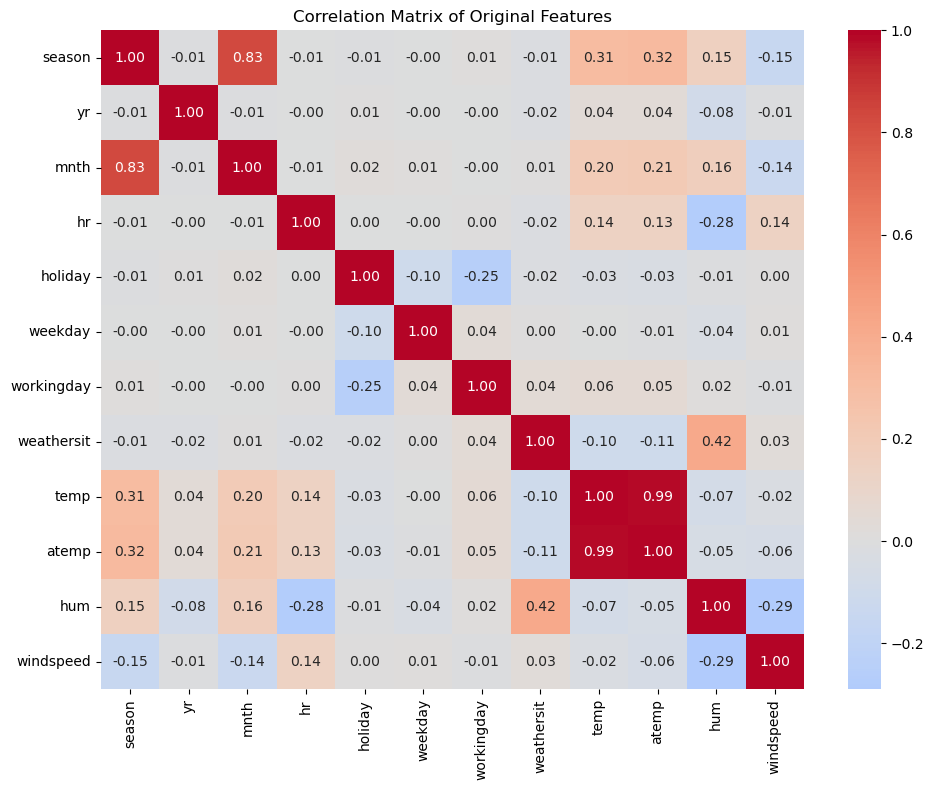

In [5]:
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation Matrix of Original Features')
plt.tight_layout()
plt.show()

In [6]:
high_corr_pairs = []
for i in range(len(corr_matrix.columns)):
    for j in range(i + 1, len(corr_matrix.columns)):
        r_val = corr_matrix.iloc[i, j]
        if abs(r_val) > 0.90:
            high_corr_pairs.append((corr_matrix.columns[i], corr_matrix.columns[j], round(r_val, 4)))

print('Highly correlated pairs (|r| > 0.90):', high_corr_pairs)

Highly correlated pairs (|r| > 0.90): [('temp', 'atemp', 0.9877)]


### Variance & Correlation Decisions
- **High Correlation (`temp` & `atemp`, $r = 0.99$):** **Decision: Drop `atemp`.** Ambient temperature (`temp`) and feeling temperature (`atemp`) are nearly collinear ($r = 0.99$).

## 4. Train/Test Split & Baseline Cross-Validation

We split the dataset (80% train, 20% test) and evaluate every engineering step using 5-fold cross-validation ($R^2$) on the training set. Plain **RandomForestRegressor** was chosen due to non-linear feature interactions.

In [7]:
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.ensemble import RandomForestRegressor

indices = np.arange(len(y))
train_indices, test_indices = train_test_split(
    indices,
    test_size=0.2,
    random_state=42
)

In [8]:
X_original_train = X_original.iloc[train_indices].copy()
X_original_test = X_original.iloc[test_indices].copy()
y_train = y.iloc[train_indices].copy()
y_test = y.iloc[test_indices].copy()

cv_model = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)

# Baseline (dropping collinear 'atemp')
X_step0 = X_original_train.drop(columns=['atemp'])
baseline_cv = cross_val_score(cv_model, X_step0, y_train, cv=5, scoring='r2').mean()
print(f'Baseline 5-Fold CV R2 (without atemp): {baseline_cv:.4f}')

Baseline 5-Fold CV R2 (without atemp): 0.9408


## 5. Feature Engineering Steps & CV Impact

We apply four transformations sequentially on `X_original_train` and log the 5-fold CV $R^2$ change after each step:
1. Map periodic hours (24h) and months (12m) onto unit circles using `sin`/`cos`.
2. Remove false ordinal relationships across nominal categories
3. Flag working-day peak commuting hours (07:00–09:00 and 16:00–19:00).
4. Capture combined heat-humidity discomfort (`temp * hum`).

In [9]:
# Step 1: Cyclical encoding of hour and month
X_step1 = X_step0.copy()
X_step1['sin_hour'] = np.sin(2 * np.pi * X_step1['hr'] / 24)
X_step1['cos_hour'] = np.cos(2 * np.pi * X_step1['hr'] / 24)
X_step1['sin_month'] = np.sin(2 * np.pi * (X_step1['mnth'] - 1) / 12)
X_step1['cos_month'] = np.cos(2 * np.pi * (X_step1['mnth'] - 1) / 12)
X_step1 = X_step1.drop(columns=['hr', 'mnth'])

step1_cv = cross_val_score(cv_model, X_step1, y_train, cv=5, scoring='r2').mean()
print(f'Step 1 (Cyclical Time) 5-Fold CV R2: {step1_cv:.4f} (Change: {step1_cv - baseline_cv:+.4f})')


Step 1 (Cyclical Time) 5-Fold CV R2: 0.9427 (Change: +0.0019)


In [10]:
# Step 2: One-hot encoding of categorical features
X_step2 = pd.get_dummies(
    X_step1,
    columns=['weekday', 'season', 'weathersit'],
    prefix=['weekday', 'season', 'weather'],
    dtype=int
)
step2_cv = cross_val_score(cv_model, X_step2, y_train, cv=5, scoring='r2').mean()
print(f'Step 2 (One-Hot Encoding) 5-Fold CV R2: {step2_cv:.4f} (Change: {step2_cv - step1_cv:+.4f})')

Step 2 (One-Hot Encoding) 5-Fold CV R2: 0.9426 (Change: -0.0001)


In [11]:
# Step 3: Domain feature - Working-day rush-hour indicator
X_step3 = X_step2.copy()
X_step3['rush_hour'] = (
    (X_original_train['workingday'] == 1) &
    (
        X_original_train['hr'].between(7, 9) |
        X_original_train['hr'].between(16, 19)
    )
).astype(int)
step3_cv = cross_val_score(cv_model, X_step3, y_train, cv=5, scoring='r2').mean()
print(f'Step 3 (Rush Hour Feature) 5-Fold CV R2: {step3_cv:.4f} (Change: {step3_cv - step2_cv:+.4f})')

Step 3 (Rush Hour Feature) 5-Fold CV R2: 0.9439 (Change: +0.0014)


In [12]:
# Step 4: Interaction feature - Temperature * Humidity
X_step4 = X_step3.copy()
X_step4['temp_hum'] = X_step4['temp'] * X_step4['hum']
step4_cv = cross_val_score(cv_model, X_step4, y_train, cv=5, scoring='r2').mean()
print(f'Step 4 (Temp*Hum Interaction) 5-Fold CV R2: {step4_cv:.4f} (Change: {step4_cv - step3_cv:+.4f})')

Step 4 (Temp*Hum Interaction) 5-Fold CV R2: 0.9437 (Change: -0.0002)


In [13]:
X_engineered_train = X_step4.copy()
display(X_engineered_train.head())
print('Engineered training features shape:', X_engineered_train.shape)

,yr,holiday,workingday,temp,hum,windspeed,sin_hour,cos_hour,sin_month,cos_month,...,season_1,season_2,season_3,season_4,weather_1,weather_2,weather_3,weather_4,rush_hour,temp_hum
335,0,0,0,0.20,0.55,0.2239,0.258819,-9.659258e-01,0.0,1.000000e+00,...,1,0,0,0,1,0,0,0,0,0.1100
7035,0,0,1,0.52,0.42,0.1045,-1.000000,-1.836970e-16,-1.0,-1.836970e-16,...,0,0,0,1,1,0,0,0,1,0.2184
8051,0,0,1,0.46,1.00,0.2239,0.707107,7.071068e-01,-0.5,8.660254e-01,...,0,0,0,1,0,0,1,0,0,0.4600
2133,0,0,0,0.46,0.31,0.0000,-1.000000,-1.836970e-16,1.0,6.123234e-17,...,0,1,0,0,0,1,0,0,0,0.1426
8485,0,0,0,0.20,0.75,0.1045,1.000000,6.123234e-17,-0.5,8.660254e-01,...,1,0,0,0,1,0,0,0,0,0.1500


Engineered training features shape: (13903, 27)


- Cyclical encoding preserves midnight/year-end continuity for distance- and linear-based models.
- `One-Hot Encoding`, `Rush Hour Indicator` and `Temp 	imes Humidity Interaction` improves CV $R^2$

## 6. Feature Selection (Comparing 2 Methods)

We compare two distinct selection methods on the 27 engineered training features:
1. `SelectKBest` (`f_regression`, $k=15$)
2. Tree-Based Feature Importances (`SelectFromModel` with `RandomForestRegressor`)

In [14]:
from sklearn.feature_selection import SelectKBest, f_regression, SelectFromModel

feature_names = X_engineered_train.columns.tolist()

# Method 1: SelectKBest (univariate f_regression)
skb_selector = SelectKBest(score_func=f_regression, k=15)
skb_selector.fit(X_engineered_train, y_train)
skb_selected = X_engineered_train.columns[skb_selector.get_support()].tolist()
skb_removed = [f for f in feature_names if f not in skb_selected]
skb_cv = cross_val_score(cv_model, X_engineered_train[skb_selected], y_train, cv=5, scoring='r2').mean()

In [15]:
# Method 2: Tree-based feature importances (SelectFromModel)
rf_selector = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
sfm_selector = SelectFromModel(rf_selector, threshold='median')
sfm_selector.fit(X_engineered_train, y_train)
sfm_selected = X_engineered_train.columns[sfm_selector.get_support()].tolist()
sfm_removed = [f for f in feature_names if f not in sfm_selected]
sfm_cv = cross_val_score(cv_model, X_engineered_train[sfm_selected], y_train, cv=5, scoring='r2').mean()

In [16]:
# Side-by-side comparison table
selection_comparison = pd.DataFrame({
    'Method': ['SelectKBest (f_regression, k=15)', 'Tree-Based Importances (Median Threshold)'],
    'Selected Count': [len(skb_selected), len(sfm_selected)],
    'Removed Count': [len(skb_removed), len(sfm_removed)],
    '5-Fold CV R2': [round(skb_cv, 4), round(sfm_cv, 4)],
    'Features Selected': [', '.join(skb_selected), ', '.join(sfm_selected)],
    'Features Removed': [', '.join(skb_removed), ', '.join(sfm_removed)]
})

display(selection_comparison)

,Method,Selected Count,Removed Count,5-Fold CV R2,Features Selected,Features Removed
0,"SelectKBest (f_regression, k=15)",15,12,0.8759,"yr, temp, hum, windspeed, sin_hour, cos_hour, ...","holiday, workingday, weekday_0, weekday_1, wee..."
1,Tree-Based Importances (Median Threshold),14,13,0.9328,"yr, workingday, temp, hum, windspeed, sin_hour...","holiday, weekday_0, weekday_1, weekday_2, week..."


### Feature Selection Decision
- **Chosen Method:** **Tree-Based Feature Importances (`SelectFromModel`)**, selecting **14 features** and outperforming `SelectKBest` in 5-fold CV $R^2$.
- Hourly bike demand depends strongly on non-linear cyclical signals (`sin_hour`, `cos_hour`) and interaction terms (`rush_hour`). Moreover, tree-based importances retain key temporal, weather, and working-day predictors.
- **14 features** enter the final model.

### Feature Importance Visualization (Random Forest)
The plot below illustrates the relative importance of all 27 engineered features as ranked by the `RandomForestRegressor` used in `SelectFromModel`, along with the median threshold cut-off.

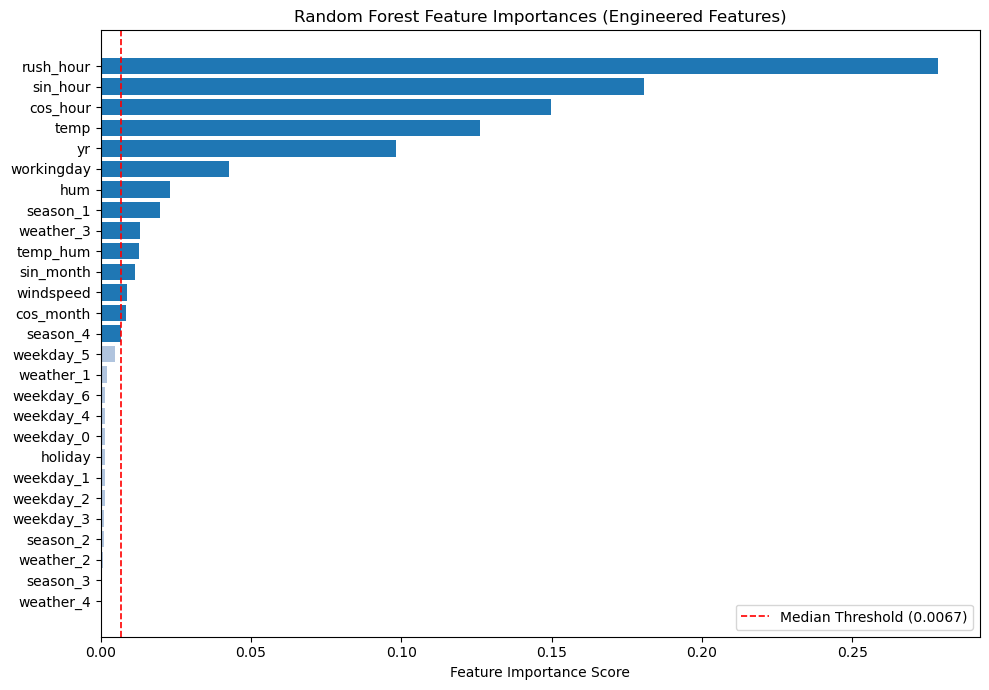

In [17]:
# Plot feature importances from the fitted RandomForestRegressor in SelectFromModel
importances = sfm_selector.estimator_.feature_importances_
feat_imp_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=True)

median_threshold = np.median(importances)

plt.figure(figsize=(10, 7))
colors = ['#1f77b4' if imp >= median_threshold else '#b0c4de' for imp in feat_imp_df['Importance']]
plt.barh(feat_imp_df['Feature'], feat_imp_df['Importance'], color=colors)
plt.axvline(median_threshold, color='red', linestyle='--', linewidth=1.2, label=f'Median Threshold ({median_threshold:.4f})')
plt.xlabel('Feature Importance Score')
plt.title('Random Forest Feature Importances (Engineered Features)')
plt.legend()
plt.tight_layout()
plt.show()

Time-of-day features dominate the model: rush_hour (~0.28), sin_hour (~0.18), and cos_hour (~0.15), followed by temperature (temp, ~0.13) and year (yr, ~0.10). Together, these five features account for roughly 84% of total feature importance. Out of 27 total features, 14 meet or exceed the median importance threshold of 0.0067.

## 7. Dimensionality Reduction

- After feature selection, the dataset has **14 features** ($\le 20$ features). PCA is **not applied** (N/A — full marks applicable) because the selected feature set is already low-dimensional and directly interpretable.
- We fit `StandardScaler` and `TSNE` on a random subsample of `X_train` only (preventing data leakage) to inspect demand tier separability.

In [18]:
from sklearn.preprocessing import StandardScaler
from sklearn.manifold import TSNE

# Fit StandardScaler and t-SNE strictly on X_train subset (no test leakage)
X_train_selected = X_engineered_train[sfm_selected]
rng = np.random.RandomState(42)
vis_idx = rng.choice(len(X_train_selected), size=2000, replace=False)

X_vis_scaled = StandardScaler().fit_transform(X_train_selected.iloc[vis_idx])
y_vis_bins = pd.qcut(y_train.iloc[vis_idx], q=3, labels=['Low Demand', 'Medium Demand', 'High Demand'])

Exception in thread Thread-1413 (_readerthread):
Traceback (most recent call last):
  File "c:\Users\user\anaconda3\Lib\threading.py", line 1045, in _bootstrap_inner
    self.run()
  File "c:\Users\user\anaconda3\Lib\threading.py", line 982, in run
    self._target(*self._args, **self._kwargs)
  File "c:\Users\user\anaconda3\Lib\subprocess.py", line 1597, in _readerthread
    buffer.append(fh.read())
                  ^^^^^^^^^
  File "<frozen codecs>", line 322, in decode
UnicodeDecodeError: 'utf-8' codec can't decode byte 0x8d in position 4: invalid start byte


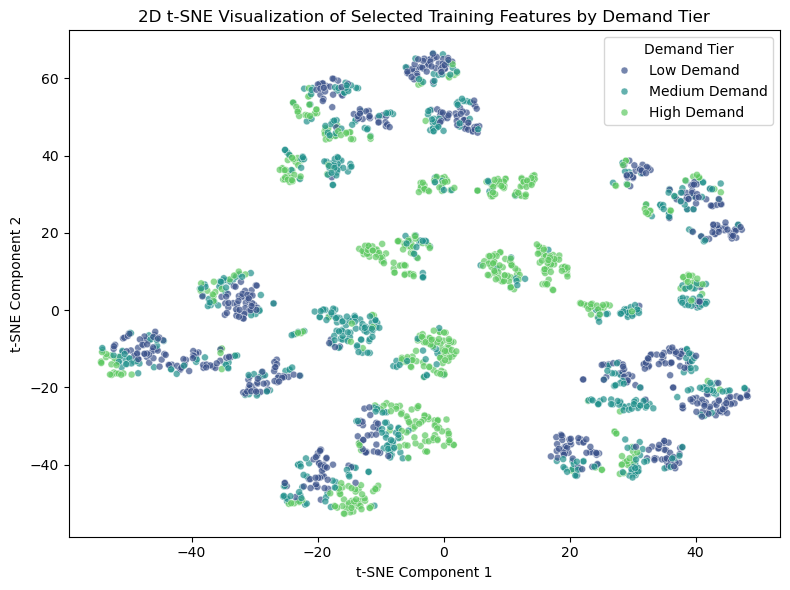

In [19]:
tsne = TSNE(n_components=2, random_state=42, perplexity=30)
X_tsne = tsne.fit_transform(X_vis_scaled)

plt.figure(figsize=(8, 6))
sns.scatterplot(x=X_tsne[:, 0], y=X_tsne[:, 1], hue=y_vis_bins, palette='viridis', alpha=0.7, s=25)
plt.title('2D t-SNE Visualization of Selected Training Features by Demand Tier')
plt.xlabel('t-SNE Component 1')
plt.ylabel('t-SNE Component 2')
plt.legend(title='Demand Tier')
plt.tight_layout()
plt.show()

### 2D t-SNE Interpretation
The 2D t-SNE projection reveals well-separated clusters corresponding to working-day, rush-hour, and seasonal regimes:
- **High Demand** hours cluster tightly in daytime commuter and warm-weather regions
- **Low Demand** hours separate into overnight and colder-weather clusters, confirming strong separability in the selected 14-feature space.

## 8. Complete Self-Contained `sklearn` Pipeline

All preprocessing steps are integrated into a single `sklearn` `Pipeline` using `ColumnTransformer`.

In [20]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [ ]:
# Custom transformer encapsulating deterministic feature engineering inside the Pipeline
class BikeFeatureEngineer(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X_out = X.copy()
        # Cyclical time encoding
        X_out['sin_hour'] = np.sin(2 * np.pi * X_out['hr'] / 24)
        X_out['cos_hour'] = np.cos(2 * np.pi * X_out['hr'] / 24)
        X_out['sin_month'] = np.sin(2 * np.pi * (X_out['mnth'] - 1) / 12)
        X_out['cos_month'] = np.cos(2 * np.pi * (X_out['mnth'] - 1) / 12)
        
        # Working-day rush hour indicator and temperature-humidity interaction
        X_out['rush_hour'] = (
            (X_out['workingday'] == 1) &
            (X_out['hr'].between(7, 9) | X_out['hr'].between(16, 19))
        ).astype(int)
        X_out['temp_hum'] = X_out['temp'] * X_out['hum']
        
        # Drop raw cyclical columns and collinear 'atemp'
        return X_out.drop(columns=['hr', 'mnth', 'atemp'])

In [ ]:
num_features = ['yr', 'holiday', 'workingday', 'temp', 'hum', 'windspeed',
                'sin_hour', 'cos_hour', 'sin_month', 'cos_month', 'rush_hour', 'temp_hum']
cat_features = ['weekday', 'season', 'weathersit']

numeric_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_pipeline, num_features),
    ('cat', categorical_pipeline, cat_features)
])

# Complete self-contained sklearn Pipeline
final_pipeline = Pipeline(steps=[
    ('feature_engineering', BikeFeatureEngineer()),
    ('preprocessor', preprocessor),
    ('feature_selection', SelectFromModel(
        RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1),
        threshold='median'
    )),
    ('estimator', RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1))
])

In [ ]:
final_pipeline.fit(X_original_train, y_train)

X_train_processed = final_pipeline[:-1].transform(X_original_train)
X_test_processed = final_pipeline[:-1].transform(X_original_test)
y_test_pred = final_pipeline.predict(X_original_test)

print('X_train transformed shape:', X_train_processed.shape)
print('X_test transformed shape: ', X_test_processed.shape)
print('y_test predictions shape: ', y_test_pred.shape)
print(f'Test MAE:  {mean_absolute_error(y_test, y_test_pred):.4f}')
print(f'Test RMSE: {np.sqrt(mean_squared_error(y_test, y_test_pred)):.4f}')
print(f'Test R2:   {r2_score(y_test, y_test_pred):.4f}')

X_train transformed shape: (13903, 14)
X_test transformed shape:  (3476, 14)
y_test predictions shape:  (3476,)
Test MAE:  28.0985
Test RMSE: 46.0320
Test R2:   0.9331
